In [6]:
import pandas as pd
import json
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("Biblioteker lastet inn!")

Biblioteker lastet inn!


In [10]:
# Last inn klassifiserte data
with open("../data/klassifisert.json", "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)
print(f"Lastet {len(df)} klassifiserte diagnoser")
df.head()

Lastet 3103 klassifiserte diagnoser


,id,diagnosis,diagnosis_clean,kategori
0,04DD8FF1-66C0-453E-BFCF-A576624862E6,hysteria ?,hysteria ?,1. Hysteria
1,10478F81-98D2-4F83-8EA6-1EDF1811680C,hysteria 7,hysteria 7,1. Hysteria
2,97883cca-48aa-46f1-bab0-57f234b2f598,hysteria,hysteria,1. Hysteria
3,E8F128A2-502F-47E8-B73F-6566E52D4B95,202|hysteria,202|hysteria,1. Hysteria
4,8F1CC767-D817-4334-B717-D493D2EBC80B,hysteria,hysteria,1. Hysteria


In [ ]:
import numpy as np

# Ta 100 tilfeldige poster, disse er helt tilfeldige - ikke stratifisert
df_sample = df.sample(n=min(100, len(df)), random_state=42).copy()

# Legg til en tom kolonne for din manuelle vurdering
df_sample["fasit"] = ""

# Lagre som ExCel - enkel å åpne i Excel
df_sample[["id", "diagnosis", "kategori", "fasit"]].to_excel(
    "../data/gullstandard.xlsx", 
    index=False
)
print(f"Lagret {len(df_sample)} poster til gullstandard.xlsx")
print("Åpne filen i Excel, fyll inn kolonne 'fasit' med tall 1-5, lagre og kom tilbake!")

Lagret 100 poster til gullstandard.xlsx
Åpne filen i Excel, fyll inn kolonne 'fasit' med tall 1-5, lagre og kom tilbake!


In [5]:


# Opprinnelig: tilfeldig utvalg på 100 poster
# Byttet til stratifisert utvalg (se neste celle) fordi 
# tilfeldig utvalg ikke garanterer representasjon av sjeldne kategorier
# df_sample = df.sample(n=min(100, len(df)), random_state=42).copy()

# Ta 20 fra hver kategori for balansert evaluering

df_ferdig = pd.read_json("../data/klassifisert.json")

# Stratifisert utvalg med concat i stedet
df_sample = pd.concat([
    gruppe.sample(min(20, len(gruppe)), random_state=42)
    for _, gruppe in df_ferdig.groupby("kategori")
]).reset_index(drop=True)

df_sample["fasit"] = ""

df_sample[["id", "diagnosis", "kategori", "fasit"]].to_excel(
    "../data/gullstandard.xlsx", index=False
)
print(f"Lagret {len(df_sample)} poster")
print(df_sample["kategori"].value_counts())

Lagret 100 poster
kategori
1. Hysteria                  20
2. Hysterisk personlighet    20
3. Ex constitutione          20
4. Epilepsi-relatert         20
5. Annet                     20
Name: count, dtype: int64


In [12]:
# Last inn din manuelle vurdering
df_fasit = pd.read_excel("../data/gullstandard.xlsx")

# Fjern rader uten fasit
df_fasit = df_fasit[df_fasit["fasit"].notna()]
df_fasit = df_fasit[df_fasit["fasit"] != ""]

print(f"Antall manuelt vurderte: {len(df_fasit)}")
print(f"\nGemma vs. din vurdering:")
df_fasit[["id", "diagnosis", "kategori", "fasit"]]

Antall manuelt vurderte: 100

Gemma vs. din vurdering:


,id,diagnosis,kategori,fasit
0,d7b8e334-6472-416f-a6a1-e3f4bc058302,hysteria,1. Hysteria,1
1,15618244-8e53-4b76-afed-f9a30f481600,insania hysterica (dem. præc.?),1. Hysteria,1
2,2d74e1f0-13e3-4ecf-b795-2c439c92dd1d,hysteria,1. Hysteria,1
3,1831ecb2-4695-4558-b144-5dde8c8fafd4,hysteri form,1. Hysteria,1
4,e1247946-ee71-4814-ac17-7df9444122dd,hysteria,1. Hysteria,1
...,...,...,...,...
95,7a32053b-a9d1-47c3-81e4-5327e7de2cc5,hysteria. miliartuberkulose,5. Annet,1
96,9bc2adba-380b-4e53-bd16-c22d9c9fe3ee,depressio nevrose hysterikse trekk,5. Annet,5
97,BFA7CC21-0645-4ECB-9226-5C0713EC9CF0,reaktiv depresjon m. hysterisk hell ikke lesbart,5. Annet,5
98,45fad832-fdfb-45c6-b1fc-9ca755a80694,psykopathia affektflatie hysteriform,5. Annet,5


In [7]:
# Hent bare nummeret fra Gemma sin kategori
df_fasit["kategori_nr"] = df_fasit["kategori"].str[0]
df_fasit["fasit_str"] = df_fasit["fasit"].astype(str).str[0]

riktige = (df_fasit["kategori_nr"] == df_fasit["fasit_str"]).sum()
totalt = len(df_fasit)
nøyaktighet = riktige / totalt * 100

print(f"Riktige: {riktige} av {totalt}")
print(f"Nøyaktighet: {nøyaktighet:.1f}%")

for _, rad in df_fasit.iterrows():
    riktig = "✅" if rad["kategori_nr"] == rad["fasit_str"] else "❌"
    print(f"  {riktig} {rad['id']}: Gemma={rad['kategori']} | Fasit={rad['fasit']}")

Riktige: 92 av 100
Nøyaktighet: 92.0%
  ✅ f4c9915a-4cca-4d6b-b59b-446324227152: Gemma=1. Hysteria | Fasit=1
  ✅ 2136bdde-1169-493a-8c95-5f6ef7fcfb33: Gemma=1. Hysteria | Fasit=1
  ✅ a6c2663b-3e97-4652-8bda-0c8da7ec45b0: Gemma=1. Hysteria | Fasit=1
  ✅ 546714ba-d251-4af2-8f38-1f7ec8da2c1b: Gemma=3. Ex constitutione | Fasit=3
  ✅ 3b619f2a-790c-4650-9dab-2085619eee89: Gemma=1. Hysteria | Fasit=1
  ✅ 9b49f3cc-d8b4-45f1-b277-f638c5badd76: Gemma=3. Ex constitutione | Fasit=3
  ✅ a53540a5-33a7-4f61-84e0-331561936dc5: Gemma=3. Ex constitutione | Fasit=3
  ✅ 2372d65e-fac6-4a2a-8ef2-cad30e018b0e: Gemma=1. Hysteria | Fasit=1
  ✅ 715ae9e0-1080-4682-96a2-26e93eaf2ccc: Gemma=3. Ex constitutione | Fasit=3
  ✅ 607530d3-b994-4146-95dd-bcb625c30429: Gemma=3. Ex constitutione | Fasit=3
  ✅ ec734849-2a9e-4315-a9e0-704eff6c97e3: Gemma=3. Ex constitutione | Fasit=3
  ✅ 2b65f382-a864-4795-9e83-f731bb0ed328: Gemma=3. Ex constitutione | Fasit=3
  ❌ 45fad832-fdfb-45c6-b1fc-9ca755a80694: Gemma=5. Annet | Fasit=1

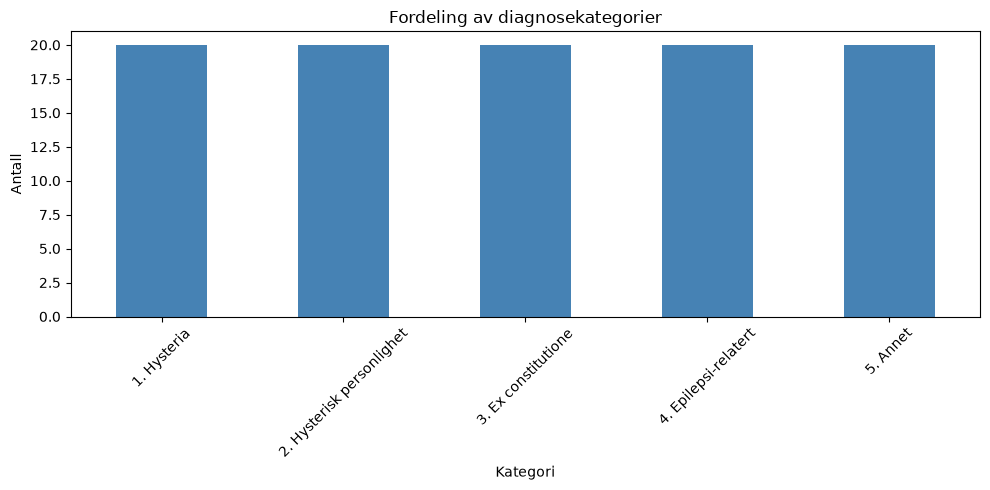

Plot lagret!


In [13]:
# Tell opp kategorier
kategori_telling = df_fasit["kategori"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
kategori_telling.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Fordeling av diagnosekategorier")
ax.set_xlabel("Kategori")
ax.set_ylabel("Antall")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("../results/kategori_fordeling.png", dpi=150)
plt.show()

print("Plot lagret!")

In [15]:
from sklearn.metrics import classification_report
import pandas as pd

# Sørg for at kolonnene finnes
df_fasit["kategori_nr"] = df_fasit["kategori"].str[0]
df_fasit["fasit_str"] = df_fasit["fasit"].astype(str).str[0]


# Lag rapport som dictionary
rapport = classification_report(
    df_fasit["fasit_str"], 
    df_fasit["kategori_nr"],
    zero_division=0,
    output_dict=True
)

# Gjør om til pen tabell
df_rapport = pd.DataFrame(rapport).T
df_rapport = df_rapport.round(2)

# Bytt ut tallkoder med kategorinavn
kategorinavn = {
    "1": "Hysteria",
    "2": "Hysterisk personlighet",
    "3": "Ex constitutione",
    "4": "Epilepsi-relatert",
    "5": "Annet",
    "accuracy": "Nøyaktighet",
    "macro avg": "Makro gjennomsnitt",
    "weighted avg": "Vektet gjennomsnitt"
}
df_rapport.index = df_rapport.index.map(lambda x: kategorinavn.get(x, x))

# Vis tabellen
df_rapport[["precision", "recall", "f1-score", "support"]].style\
    .background_gradient(subset=["precision", "recall", "f1-score"], cmap="Greens")\
    .format({"precision": "{:.2f}", "recall": "{:.2f}", 
             "f1-score": "{:.2f}", "support": "{:.0f}"})

,precision,recall,f1-score,support
Hysteria,0.95,0.86,0.90,22
Hysterisk personlighet,0.95,0.63,0.76,30
Ex constitutione,1.00,1.00,1.00,20
Epilepsi-relatert,0.50,1.00,0.67,10
Annet,0.85,0.94,0.89,18
Nøyaktighet,0.85,0.85,0.85,1
Makro gjennomsnitt,0.85,0.89,0.85,100
Vektet gjennomsnitt,0.90,0.85,0.85,100
